In [102]:
import pandas as pd
import numpy as np

products = pd.read_csv("../data/products.csv")
suppliers = pd.read_csv("../data/suppliers.csv")
inventory = pd.read_csv("../data/inventory.csv")
sales = pd.read_csv("../data/sales.csv")

In [103]:
products.head()


,product_id,product_name,category,unit_cost,supplier_id,reorder_threshold,selling_price
0,1,Laptop,Electronics,112,2,83,145.6
1,2,Mouse,Accessories,445,4,22,578.5
2,3,Keyboard,Accessories,280,2,70,364.0
3,4,Monitor,Electronics,116,4,26,150.8
4,5,Headphones,Accessories,81,5,40,105.3


In [104]:
inventory.head()

,product_id,warehouse,stock_quantity,safety_stock
0,1,Dhaka,210,26
1,1,Chattogram,168,27
2,1,Sylhet,108,13
3,2,Dhaka,6,39
4,2,Chattogram,138,31


In [105]:
sales.head()


,date,product_id,warehouse,units_sold
0,2025-01-01,1,Sylhet,7
1,2025-01-01,2,Chattogram,5
2,2025-01-01,3,Sylhet,3
3,2025-01-01,4,Sylhet,3
4,2025-01-01,5,Sylhet,4


In [106]:
print("Products:", products.shape)
print("Suppliers:", suppliers.shape)
print("Inventory:", inventory.shape)
print("Sales:", sales.shape)


Products: (20, 7)
Suppliers: (5, 4)
Inventory: (60, 4)
Sales: (7300, 4)


In [107]:
suppliers.info()


<class 'pandas.DataFrame'>
RangeIndex: 5 entries, 0 to 4
Data columns (total 4 columns):
 #   Column                   Non-Null Count  Dtype
---  ------                   --------------  -----
 0   supplier_id              5 non-null      int64
 1   supplier_name            5 non-null      str  
 2   region                   5 non-null      str  
 3   expected_lead_time_days  5 non-null      int64
dtypes: int64(2), str(2)
memory usage: 292.0 bytes


In [108]:
inventory.info()

<class 'pandas.DataFrame'>
RangeIndex: 60 entries, 0 to 59
Data columns (total 4 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   product_id      60 non-null     int64
 1   warehouse       60 non-null     str  
 2   stock_quantity  60 non-null     int64
 3   safety_stock    60 non-null     int64
dtypes: int64(3), str(1)
memory usage: 2.0 KB


In [109]:
sales.info()

<class 'pandas.DataFrame'>
RangeIndex: 7300 entries, 0 to 7299
Data columns (total 4 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   date        7300 non-null   str  
 1   product_id  7300 non-null   int64
 2   warehouse   7300 non-null   str  
 3   units_sold  7300 non-null   int64
dtypes: int64(2), str(2)
memory usage: 228.3 KB


In [110]:
products.isnull().sum()

product_id           0
product_name         0
category             0
unit_cost            0
supplier_id          0
reorder_threshold    0
selling_price        0
dtype: int64

In [111]:
print("Products missing values:")
print(products.isnull().sum())

print("\nSuppliers missing values:")
print(suppliers.isnull().sum())

print("\nInventory missing values:")
print(inventory.isnull().sum())

print("\nSales missing values:")
print(sales.isnull().sum())

Products missing values:
product_id           0
product_name         0
category             0
unit_cost            0
supplier_id          0
reorder_threshold    0
selling_price        0
dtype: int64

Suppliers missing values:
supplier_id                0
supplier_name              0
region                     0
expected_lead_time_days    0
dtype: int64

Inventory missing values:
product_id        0
warehouse         0
stock_quantity    0
safety_stock      0
dtype: int64

Sales missing values:
date          0
product_id    0
warehouse     0
units_sold    0
dtype: int64


In [112]:
print("Products duplicates:", products.duplicated().sum())
print("Suppliers duplicates:", suppliers.duplicated().sum())
print("Inventory duplicates:", inventory.duplicated().sum())
print("Sales duplicates:", sales.duplicated().sum())

Products duplicates: 0
Suppliers duplicates: 0
Inventory duplicates: 0
Sales duplicates: 0


In [113]:
datasets = {
    "Products": products,
    "Suppliers": suppliers,
    "Inventory": inventory,
    "Sales": sales
}

for name, df in datasets.items():

    print(f"\n--- {name} ---")
    print("Rows:", df.shape[0])
    print("Columns:", df.shape[1])
    print("Missing values:", df.isnull().sum().sum())
    print("Duplicate rows:", df.duplicated().sum())


--- Products ---
Rows: 20
Columns: 7
Missing values: 0
Duplicate rows: 0

--- Suppliers ---
Rows: 5
Columns: 4
Missing values: 0
Duplicate rows: 0

--- Inventory ---
Rows: 60
Columns: 4
Missing values: 0
Duplicate rows: 0

--- Sales ---
Rows: 7300
Columns: 4
Missing values: 0
Duplicate rows: 0


In [114]:
sales["date"] = pd.to_datetime(sales["date"])

sales.info()

<class 'pandas.DataFrame'>
RangeIndex: 7300 entries, 0 to 7299
Data columns (total 4 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   date        7300 non-null   datetime64[us]
 1   product_id  7300 non-null   int64         
 2   warehouse   7300 non-null   str           
 3   units_sold  7300 non-null   int64         
dtypes: datetime64[us](1), int64(2), str(1)
memory usage: 228.3 KB


In [115]:
print("Negative stock:")
print(inventory[inventory["stock_quantity"] < 0])

print("\nNegative safety stock:")
print(inventory[inventory["safety_stock"] < 0])

print("\nNegative sales:")
print(sales[sales["units_sold"] < 0])

print("\nNegative product cost:")
print(products[products["unit_cost"] < 0])

print("\nNegative selling price:")
print(products[products["selling_price"] < 0])

Negative stock:
Empty DataFrame
Columns: [product_id, warehouse, stock_quantity, safety_stock]
Index: []

Negative safety stock:
Empty DataFrame
Columns: [product_id, warehouse, stock_quantity, safety_stock]
Index: []

Negative sales:
Empty DataFrame
Columns: [date, product_id, warehouse, units_sold]
Index: []

Negative product cost:
Empty DataFrame
Columns: [product_id, product_name, category, unit_cost, supplier_id, reorder_threshold, selling_price]
Index: []

Negative selling price:
Empty DataFrame
Columns: [product_id, product_name, category, unit_cost, supplier_id, reorder_threshold, selling_price]
Index: []


In [116]:
print("Duplicate product IDs:")
print(products["product_id"].duplicated().sum())

print("Duplicate supplier IDs:")
print(suppliers["supplier_id"].duplicated().sum())

print("Duplicate inventory records:")
print(inventory.duplicated(
    subset=["product_id", "warehouse"]
).sum())

print("Duplicate sales records:")
print(sales.duplicated(
    subset=["date", "product_id"]
).sum())

Duplicate product IDs:
0
Duplicate supplier IDs:
0
Duplicate inventory records:
0
Duplicate sales records:
0


In [117]:
print(
    "Invalid supplier IDs in products:",
    ~products["supplier_id"].isin(suppliers["supplier_id"]).sum()
)

Invalid supplier IDs in products: -21


In [118]:
invalid_supplier_ids = ~products["supplier_id"].isin(
    suppliers["supplier_id"]
)

print("Invalid supplier IDs:", invalid_supplier_ids.sum())

Invalid supplier IDs: 0


In [119]:
invalid_inventory_products = ~inventory["product_id"].isin(
    products["product_id"]
)

invalid_sales_products = ~sales["product_id"].isin(
    products["product_id"]
)

print("Invalid inventory product IDs:", invalid_inventory_products.sum())
print("Invalid sales product IDs:", invalid_sales_products.sum())

Invalid inventory product IDs: 0
Invalid sales product IDs: 0


In [120]:
products.describe()

,product_id,unit_cost,supplier_id,reorder_threshold,selling_price
count,20.00000,20.000000,20.000000,20.000000,20.000000
mean,10.50000,321.350000,3.100000,53.150000,417.755000
std,5.91608,224.510057,1.293709,24.948948,291.863074
min,1.00000,30.000000,1.000000,21.000000,39.000000
25%,5.75000,115.000000,2.000000,27.750000,149.500000
50%,10.50000,299.000000,3.500000,56.000000,388.700000
75%,15.25000,470.000000,4.000000,73.750000,611.000000
max,20.00000,710.000000,5.000000,92.000000,923.000000


In [121]:
inventory.describe()

,product_id,stock_quantity,safety_stock
count,60.000000,60.000000,60.000000
mean,10.500000,143.866667,22.366667
std,5.814943,72.312520,8.580559
min,1.000000,5.000000,10.000000
25%,5.750000,98.500000,15.500000
50%,10.500000,150.500000,21.000000
75%,15.250000,210.000000,29.250000
max,20.000000,247.000000,39.000000


In [122]:
sales.describe()

,date,product_id,units_sold
count,7300,7300.000000,7300.000000
mean,2025-07-02 00:00:00,10.500000,5.005753
min,2025-01-01 00:00:00,1.000000,0.000000
25%,2025-04-02 00:00:00,5.750000,3.000000
50%,2025-07-02 00:00:00,10.500000,5.000000
75%,2025-10-01 00:00:00,15.250000,6.000000
max,2025-12-31 00:00:00,20.000000,15.000000
std,NaN,5.766676,2.216769


In [123]:
products_clean = products.copy()
suppliers_clean = suppliers.copy()
inventory_clean = inventory.copy()
sales_clean = sales.copy()

In [124]:
from pathlib import Path

CLEAN_DATA_DIR = Path("../data/cleaned")
CLEAN_DATA_DIR.mkdir(exist_ok=True)

products_clean.to_csv(CLEAN_DATA_DIR / "products_clean.csv", index=False)
suppliers_clean.to_csv(CLEAN_DATA_DIR / "suppliers_clean.csv", index=False)
inventory_clean.to_csv(CLEAN_DATA_DIR / "inventory_clean.csv", index=False)
sales_clean.to_csv(CLEAN_DATA_DIR / "sales_clean.csv", index=False)

In [125]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

products = pd.read_csv("../data/cleaned/products_clean.csv")
suppliers = pd.read_csv("../data/cleaned/suppliers_clean.csv")
inventory = pd.read_csv("../data/cleaned/inventory_clean.csv")
sales = pd.read_csv("../data/cleaned/sales_clean.csv")

sales["date"] = pd.to_datetime(sales["date"])

print("All datasets loaded successfully!")

All datasets loaded successfully!


In [126]:
import sys
!{sys.executable} -m pip install matplotlib seaborn



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [127]:
product_sales = (
    sales.groupby("product_id")["units_sold"]
    .sum()
    .reset_index()
)

product_sales = product_sales.merge(
    products[["product_id", "product_name", "category"]],
    on="product_id"
)

product_sales = product_sales.sort_values(
    by="units_sold",
    ascending=False
)

product_sales.head(10)

,product_id,units_sold,product_name,category
17,18,1917,Charger,Accessories
13,14,1877,Power Bank,Accessories
11,12,1871,SSD,Storage
10,11,1862,USB Drive,Storage
9,10,1855,Tablet,Electronics
3,4,1852,Monitor,Electronics
5,6,1847,Printer,Electronics
14,15,1843,Speaker,Accessories
4,5,1837,Headphones,Accessories
7,8,1833,Router,Electronics


In [128]:
category_sales = (
    product_sales.groupby("category")["units_sold"]
    .sum()
    .reset_index()
    .sort_values("units_sold", ascending=False)
)

category_sales

,category,units_sold
0,Accessories,14690
2,Electronics,12755
3,Storage,5513
1,Components,3584


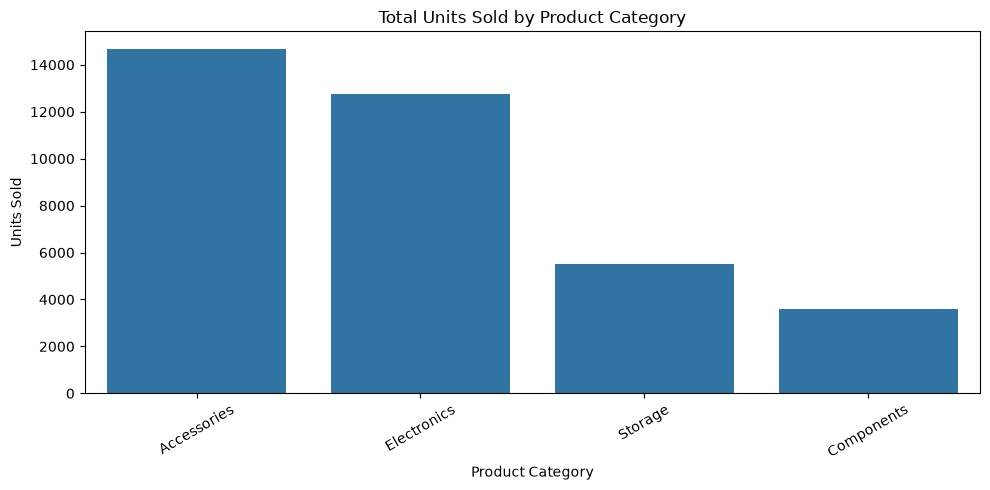

In [129]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=category_sales,
    x="category",
    y="units_sold"
)

plt.title("Total Units Sold by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Units Sold")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

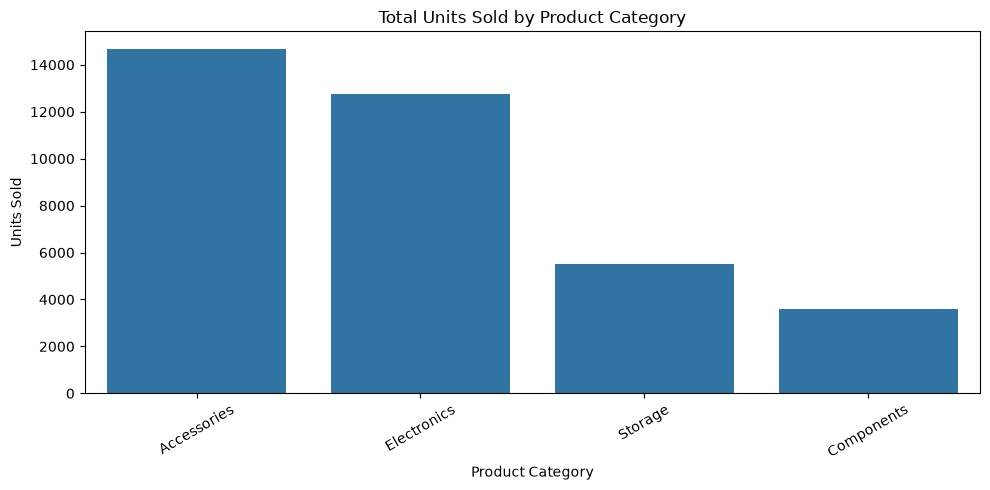

In [130]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=category_sales,
    x="category",
    y="units_sold"
)

plt.title("Total Units Sold by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Units Sold")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

In [131]:
sales["month"] = sales["date"].dt.to_period("M")

monthly_sales = (
    sales.groupby("month")["units_sold"]
    .sum()
    .reset_index()
)

monthly_sales["month"] = monthly_sales["month"].astype(str)

monthly_sales

,month,units_sold
0,2025-01,3098
1,2025-02,2792
2,2025-03,3035
3,2025-04,3027
4,2025-05,3103
5,2025-06,3091
6,2025-07,3163
7,2025-08,3103
8,2025-09,2967
9,2025-10,3072


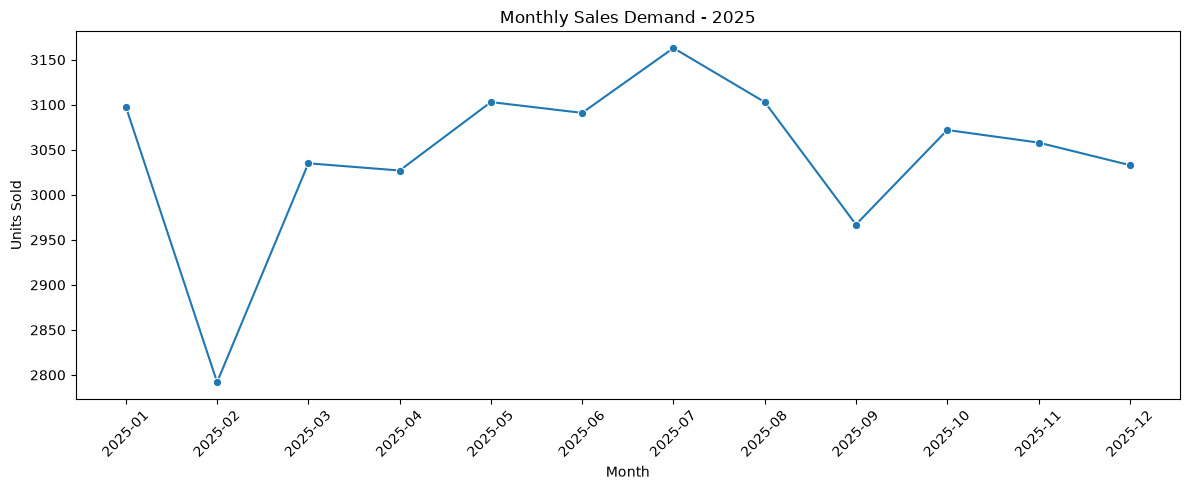

In [132]:
plt.figure(figsize=(12, 5))

sns.lineplot(
    data=monthly_sales,
    x="month",
    y="units_sold",
    marker="o"
)

plt.title("Monthly Sales Demand - 2025")
plt.xlabel("Month")
plt.ylabel("Units Sold")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [133]:
warehouse_stock = (
    inventory.groupby("warehouse")["stock_quantity"]
    .sum()
    .reset_index()
    .sort_values("stock_quantity", ascending=False)
)

warehouse_stock

,warehouse,stock_quantity
0,Chattogram,3279
1,Dhaka,2842
2,Sylhet,2511


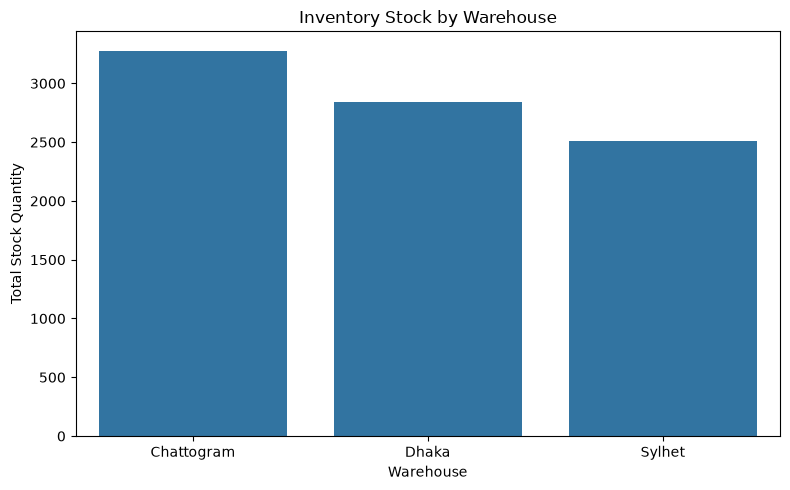

In [134]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=warehouse_stock,
    x="warehouse",
    y="stock_quantity"
)

plt.title("Inventory Stock by Warehouse")
plt.xlabel("Warehouse")
plt.ylabel("Total Stock Quantity")
plt.tight_layout()
plt.show()

In [135]:
inventory_value = inventory.merge(
    products[["product_id", "product_name", "unit_cost", "category"]],
    on="product_id"
)

inventory_value["inventory_value"] = (
    inventory_value["stock_quantity"] *
    inventory_value["unit_cost"]
)

inventory_value.head()

,product_id,warehouse,stock_quantity,safety_stock,product_name,unit_cost,category,inventory_value
0,1,Dhaka,210,26,Laptop,112,Electronics,23520
1,1,Chattogram,168,27,Laptop,112,Electronics,18816
2,1,Sylhet,108,13,Laptop,112,Electronics,12096
3,2,Dhaka,6,39,Mouse,445,Accessories,2670
4,2,Chattogram,138,31,Mouse,445,Accessories,61410


In [136]:
total_inventory_value = inventory_value["inventory_value"].sum()

print("Total Inventory Value:", round(total_inventory_value, 2))

Total Inventory Value: 2869931


In [137]:
category_inventory_value = (
    inventory_value.groupby("category")["inventory_value"]
    .sum()
    .reset_index()
    .sort_values("inventory_value", ascending=False)
)

category_inventory_value

,category,inventory_value
2,Electronics,1302474
0,Accessories,637085
1,Components,491880
3,Storage,438492


In [138]:
product_inventory = (
    inventory.groupby("product_id")["stock_quantity"]
    .sum()
    .reset_index()
)

product_inventory = product_inventory.merge(
    products[["product_id", "product_name", "reorder_threshold"]],
    on="product_id"
)

product_inventory["stock_status"] = np.where(
    product_inventory["stock_quantity"] <= product_inventory["reorder_threshold"],
    "Low Stock",
    "Sufficient Stock"
)

product_inventory.sort_values(
    "stock_quantity",
    ascending=True
)

,product_id,stock_quantity,product_name,reorder_threshold,stock_status
8,9,239,Smartphone,23,Sufficient Stock
1,2,254,Mouse,22,Sufficient Stock
12,13,294,RAM,72,Sufficient Stock
15,16,320,Microphone,90,Sufficient Stock
3,4,378,Monitor,26,Sufficient Stock
16,17,399,Smart Watch,63,Sufficient Stock
11,12,422,SSD,28,Sufficient Stock
4,5,423,Headphones,40,Sufficient Stock
17,18,433,Charger,27,Sufficient Stock
10,11,434,USB Drive,33,Sufficient Stock


In [139]:
low_stock_count = (
    product_inventory["stock_status"] == "Low Stock"
).sum()

print("Products requiring stock attention:", low_stock_count)

Products requiring stock attention: 0


In [140]:
sales_analysis = sales.merge(
    products[["product_id", "product_name", "category", "selling_price"]],
    on="product_id"
)

sales_analysis["revenue"] = (
    sales_analysis["units_sold"] *
    sales_analysis["selling_price"]
)

total_revenue = sales_analysis["revenue"].sum()

print("Estimated Total Revenue:", round(total_revenue, 2))

Estimated Total Revenue: 15226342.3


In [141]:
top_revenue_products = (
    sales_analysis.groupby("product_name")["revenue"]
    .sum()
    .reset_index()
    .sort_values("revenue", ascending=False)
    .head(10)
)

top_revenue_products

,product_name,revenue
10,Printer,1704781.0
14,Smart Watch,1579194.5
1,Graphics Card,1561417.0
12,Router,1486929.6
17,Tablet,1147874.0
11,RAM,1091469.6
8,Mouse,1037829.0
16,Speaker,915233.8
13,SSD,826982.0
2,Hard Drive,735852.0


In [142]:
import sqlite3
import pandas as pd

connection = sqlite3.connect("../data/supply_chain.db")

print("Connected to SQLite database!")

Connected to SQLite database!


In [143]:
query = """
SELECT name
FROM sqlite_master
WHERE type = 'table';
"""

pd.read_sql_query(query, connection)

,name
0,products
1,suppliers
2,inventory
3,sales


In [144]:
query = """
SELECT *
FROM products
LIMIT 10;
"""

pd.read_sql_query(query, connection)

,product_id,product_name,category,unit_cost,supplier_id,reorder_threshold,selling_price
0,1,Laptop,Electronics,112,2,83,145.6
1,2,Mouse,Accessories,445,4,22,578.5
2,3,Keyboard,Accessories,280,2,70,364.0
3,4,Monitor,Electronics,116,4,26,150.8
4,5,Headphones,Accessories,81,5,40,105.3
5,6,Printer,Electronics,710,1,92,923.0
6,7,Webcam,Accessories,30,4,58,39.0
7,8,Router,Electronics,624,2,37,811.2
8,9,Smartphone,Electronics,131,5,23,170.3
9,10,Tablet,Electronics,476,4,79,618.8


In [145]:
query = """
SELECT
    p.product_name,
    SUM(s.units_sold) AS total_units_sold

FROM sales s

JOIN products p
    ON s.product_id = p.product_id

GROUP BY p.product_name

ORDER BY total_units_sold DESC

LIMIT 10;
"""

top_products_sql = pd.read_sql_query(query, connection)

top_products_sql

,product_name,total_units_sold
0,Charger,1917
1,Power Bank,1877
2,SSD,1871
3,USB Drive,1862
4,Tablet,1855
5,Monitor,1852
6,Printer,1847
7,Speaker,1843
8,Headphones,1837
9,Router,1833


In [146]:
query = """
SELECT
    p.category,
    SUM(s.units_sold) AS total_units_sold

FROM sales s

JOIN products p
    ON s.product_id = p.product_id

GROUP BY p.category

ORDER BY total_units_sold DESC;
"""

category_sales_sql = pd.read_sql_query(query, connection)

category_sales_sql

,category,total_units_sold
0,Accessories,14690
1,Electronics,12755
2,Storage,5513
3,Components,3584


In [147]:
query = """
SELECT
    p.product_name,
    SUM(i.stock_quantity) AS total_stock,
    p.unit_cost,
    SUM(i.stock_quantity * p.unit_cost) AS inventory_value

FROM inventory i

JOIN products p
    ON i.product_id = p.product_id

GROUP BY
    p.product_id,
    p.product_name,
    p.unit_cost

ORDER BY inventory_value DESC;
"""

inventory_value_sql = pd.read_sql_query(query, connection)

inventory_value_sql

,product_name,total_stock,unit_cost,inventory_value
0,Printer,573,710,406830
1,Graphics Card,528,671,354288
2,Router,451,624,281424
3,Smart Watch,399,673,268527
4,Tablet,454,476,216104
5,Speaker,528,382,201696
6,Hard Drive,622,318,197796
7,SSD,422,340,143480
8,RAM,294,468,137592
9,Keyboard,475,280,133000


In [148]:
query = """
SELECT
    p.product_name,
    SUM(i.stock_quantity) AS total_stock,
    p.reorder_threshold

FROM inventory i

JOIN products p
    ON i.product_id = p.product_id

GROUP BY
    p.product_id,
    p.product_name,
    p.reorder_threshold

HAVING SUM(i.stock_quantity) <= p.reorder_threshold

ORDER BY total_stock ASC;
"""

low_stock_sql = pd.read_sql_query(query, connection)

low_stock_sql

,product_name,total_stock,reorder_threshold


In [149]:
query = """
SELECT
    strftime('%Y-%m', date) AS month,
    SUM(units_sold) AS total_units_sold

FROM sales

GROUP BY month

ORDER BY month;
"""

monthly_sales_sql = pd.read_sql_query(query, connection)

monthly_sales_sql

,month,total_units_sold
0,2025-01,3098
1,2025-02,2792
2,2025-03,3035
3,2025-04,3027
4,2025-05,3103
5,2025-06,3091
6,2025-07,3163
7,2025-08,3103
8,2025-09,2967
9,2025-10,3072


In [150]:
query = """
SELECT
    warehouse,
    SUM(stock_quantity) AS total_stock

FROM inventory

GROUP BY warehouse

ORDER BY total_stock DESC;
"""

warehouse_sql = pd.read_sql_query(query, connection)

warehouse_sql

,warehouse,total_stock
0,Chattogram,3279
1,Dhaka,2842
2,Sylhet,2511


In [151]:
query = """
SELECT
    p.product_name,
    SUM(s.units_sold) AS total_units,
    p.selling_price,
    SUM(s.units_sold * p.selling_price) AS estimated_revenue

FROM sales s

JOIN products p
    ON s.product_id = p.product_id

GROUP BY
    p.product_id,
    p.product_name,
    p.selling_price

ORDER BY estimated_revenue DESC

LIMIT 10;
"""

revenue_sql = pd.read_sql_query(query, connection)

revenue_sql

,product_name,total_units,selling_price,estimated_revenue
0,Printer,1847,923.0,1704781.0
1,Smart Watch,1805,874.9,1579194.5
2,Graphics Card,1790,872.3,1561417.0
3,Router,1833,811.2,1486929.6
4,Tablet,1855,618.8,1147874.0
5,RAM,1794,608.4,1091469.6
6,Mouse,1794,578.5,1037829.0
7,Speaker,1843,496.6,915233.8
8,SSD,1871,442.0,826982.0
9,Hard Drive,1780,413.4,735852.0


In [152]:
connection.close()

print("Database connection closed!")

Database connection closed!


In [153]:
import pandas as pd
import numpy as np

products = pd.read_csv("../data/cleaned/products_clean.csv")
inventory = pd.read_csv("../data/cleaned/inventory_clean.csv")
sales = pd.read_csv("../data/cleaned/sales_clean.csv")

sales["date"] = pd.to_datetime(sales["date"])

In [154]:
inventory_analysis = inventory.merge(
    products[["product_id", "product_name", "unit_cost"]],
    on="product_id"
)

inventory_analysis["inventory_value"] = (
    inventory_analysis["stock_quantity"] *
    inventory_analysis["unit_cost"]
)

total_inventory_value = inventory_analysis["inventory_value"].sum()

print("Total Inventory Value:", round(total_inventory_value, 2))

Total Inventory Value: 2869931


In [155]:
total_stock = inventory["stock_quantity"].sum()

print("Total Units in Stock:", total_stock)

Total Units in Stock: 8632


In [156]:
total_days = sales["date"].nunique()

product_demand = (
    sales.groupby("product_id")["units_sold"]
    .sum()
    .reset_index()
)

product_demand["average_daily_demand"] = (
    product_demand["units_sold"] / total_days
)

product_demand = product_demand.merge(
    products[["product_id", "product_name"]],
    on="product_id"
)

product_demand.head(10)

,product_id,units_sold,average_daily_demand,product_name
0,1,1814,4.969863,Laptop
1,2,1794,4.915068,Mouse
2,3,1776,4.865753,Keyboard
3,4,1852,5.073973,Monitor
4,5,1837,5.032877,Headphones
5,6,1847,5.060274,Printer
6,7,1819,4.983562,Webcam
7,8,1833,5.021918,Router
8,9,1749,4.791781,Smartphone
9,10,1855,5.082192,Tablet


In [157]:
product_stock = (
    inventory.groupby("product_id")["stock_quantity"]
    .sum()
    .reset_index()
)

inventory_kpis = product_stock.merge(
    product_demand[
        ["product_id", "average_daily_demand"]
    ],
    on="product_id"
)

inventory_kpis["days_of_inventory"] = np.where(
    inventory_kpis["average_daily_demand"] > 0,
    inventory_kpis["stock_quantity"] /
    inventory_kpis["average_daily_demand"],
    np.nan
)

inventory_kpis = inventory_kpis.merge(
    products[["product_id", "product_name"]],
    on="product_id"
)

inventory_kpis.sort_values(
    "days_of_inventory"
).head(10)

,product_id,stock_quantity,average_daily_demand,days_of_inventory,product_name
8,9,239,4.791781,49.877073,Smartphone
1,2,254,4.915068,51.677815,Mouse
12,13,294,4.915068,59.816054,RAM
15,16,320,5.005479,63.929940,Microphone
3,4,378,5.073973,74.497840,Monitor
16,17,399,4.945205,80.684211,Smart Watch
11,12,422,5.126027,82.324960,SSD
17,18,433,5.252055,82.443923,Charger
4,5,423,5.032877,84.047360,Headphones
10,11,434,5.101370,85.075188,USB Drive


In [158]:
sales_cost = sales.merge(
    products[["product_id", "unit_cost"]],
    on="product_id"
)

sales_cost["cost_of_goods_sold"] = (
    sales_cost["units_sold"] *
    sales_cost["unit_cost"]
)

total_cogs = sales_cost["cost_of_goods_sold"].sum()

print("Estimated Annual COGS:", round(total_cogs, 2))

Estimated Annual COGS: 11712571


In [159]:
ending_inventory_value = total_inventory_value

estimated_inventory_turnover = (
    total_cogs / ending_inventory_value
)

print(
    "Estimated Inventory Turnover:",
    round(estimated_inventory_turnover, 2)
)

Estimated Inventory Turnover: 4.08


In [160]:
inventory_kpis["stockout_risk"] = np.where(
    inventory_kpis["days_of_inventory"] < 7,
    "High Risk",
    np.where(
        inventory_kpis["days_of_inventory"] < 14,
        "Medium Risk",
        "Low Risk"
    )
)

inventory_kpis[
    [
        "product_name",
        "stock_quantity",
        "average_daily_demand",
        "days_of_inventory",
        "stockout_risk"
    ]
].sort_values("days_of_inventory")

,product_name,stock_quantity,average_daily_demand,days_of_inventory,stockout_risk
8,Smartphone,239,4.791781,49.877073,Low Risk
1,Mouse,254,4.915068,51.677815,Low Risk
12,RAM,294,4.915068,59.816054,Low Risk
15,Microphone,320,5.005479,63.929940,Low Risk
3,Monitor,378,5.073973,74.497840,Low Risk
16,Smart Watch,399,4.945205,80.684211,Low Risk
11,SSD,422,5.126027,82.324960,Low Risk
17,Charger,433,5.252055,82.443923,Low Risk
4,Headphones,423,5.032877,84.047360,Low Risk
10,USB Drive,434,5.101370,85.075188,Low Risk


In [161]:
product_supplier = products.merge(
    suppliers[[
        "supplier_id",
        "expected_lead_time_days"
    ]],
    on="supplier_id"
)

In [162]:
warehouse_demand = (
    sales.groupby(
        ["product_id", "warehouse"]
    )["units_sold"]
    .sum()
    .reset_index()
)

warehouse_demand["average_daily_demand"] = (
    warehouse_demand["units_sold"] / total_days
)

In [163]:
reorder_analysis = inventory.merge(
    warehouse_demand[
        ["product_id", "warehouse", "average_daily_demand"]
    ],
    on=["product_id", "warehouse"],
    how="left"
)

reorder_analysis = reorder_analysis.merge(
    product_supplier[
        ["product_id", "expected_lead_time_days"]
    ],
    on="product_id"
)

reorder_analysis["average_daily_demand"] = (
    reorder_analysis["average_daily_demand"].fillna(0)
)

In [164]:
reorder_analysis["reorder_point"] = (
    reorder_analysis["average_daily_demand"] *
    reorder_analysis["expected_lead_time_days"]
    + reorder_analysis["safety_stock"]
)

In [165]:
reorder_analysis["reorder_status"] = np.where(
    reorder_analysis["stock_quantity"]
    <= reorder_analysis["reorder_point"],
    "Reorder Required",
    "Stock Sufficient"
)

reorder_analysis[
    [
        "product_id",
        "warehouse",
        "stock_quantity",
        "average_daily_demand",
        "expected_lead_time_days",
        "safety_stock",
        "reorder_point",
        "reorder_status"
    ]
].sort_values("stock_quantity")

,product_id,warehouse,stock_quantity,average_daily_demand,expected_lead_time_days,safety_stock,reorder_point,reorder_status
47,16,Sylhet,5,1.632877,15,14,38.493151,Reorder Required
3,2,Dhaka,6,1.671233,15,39,64.068493,Reorder Required
25,9,Chattogram,13,1.506849,6,33,42.041096,Reorder Required
11,4,Sylhet,18,1.430137,15,25,46.452055,Reorder Required
12,5,Dhaka,19,1.701370,6,17,27.208219,Reorder Required
18,7,Dhaka,28,1.583562,15,35,58.753425,Reorder Required
50,17,Sylhet,31,1.698630,15,18,43.479452,Reorder Required
34,12,Chattogram,45,1.608219,7,37,48.257534,Reorder Required
23,8,Sylhet,49,1.682192,12,10,30.186301,Stock Sufficient
38,13,Sylhet,52,1.402740,9,32,44.624658,Stock Sufficient


In [166]:
total_stock = inventory["stock_quantity"].sum()

In [167]:
kpi_summary = pd.DataFrame({
    "KPI": [
        "Total Inventory Value",
        "Total Units in Stock",
        "Average Daily Demand",
        "Estimated Annual COGS",
        "Estimated Inventory Turnover",
        "High Risk Products",
        "Products Requiring Reorder"
    ],

    "Value": [
        round(total_inventory_value, 2),
        int(total_stock),
        round(sales["units_sold"].sum() / total_days, 2),
        round(total_cogs, 2),
        round(estimated_inventory_turnover, 2),
        int((inventory_kpis["stockout_risk"] == "High Risk").sum()),
        int((reorder_analysis["reorder_status"] == "Reorder Required").sum())
    ]
})

kpi_summary

,KPI,Value
0,Total Inventory Value,2869931.00
1,Total Units in Stock,8632.00
2,Average Daily Demand,100.12
3,Estimated Annual COGS,11712571.00
4,Estimated Inventory Turnover,4.08
5,High Risk Products,0.00
6,Products Requiring Reorder,9.00


In [168]:
REPORT_DIR = Path("../reports")
REPORT_DIR.mkdir(exist_ok=True)

kpi_summary.to_csv(
    REPORT_DIR / "inventory_kpi_summary.csv",
    index=False
)

inventory_kpis.to_csv(
    REPORT_DIR / "product_inventory_kpis.csv",
    index=False
)

reorder_analysis.to_csv(
    REPORT_DIR / "reorder_analysis.csv",
    index=False
)

print("KPI reports saved successfully!")

KPI reports saved successfully!


In [169]:
purchase_orders = pd.read_csv(
    "../data/cleaned/purchase_orders.csv"
)

purchase_orders["order_date"] = pd.to_datetime(
    purchase_orders["order_date"]
)

purchase_orders["expected_delivery_date"] = pd.to_datetime(
    purchase_orders["expected_delivery_date"]
)

purchase_orders["actual_delivery_date"] = pd.to_datetime(
    purchase_orders["actual_delivery_date"]
)

print(purchase_orders.head())

   order_id  supplier_id  product_id   warehouse order_date  \
0         1            2           1       Dhaka 2025-07-11   
1         2            3          18  Chattogram 2025-03-30   
2         3            3          14  Chattogram 2025-07-10   
3         4            4          17       Dhaka 2025-06-06   
4         5            4           4  Chattogram 2025-01-28   

  expected_delivery_date actual_delivery_date  quantity_ordered  
0             2025-07-23           2025-08-02                77  
1             2025-04-08           2025-04-18                28  
2             2025-07-19           2025-07-24                33  
3             2025-06-21           2025-06-24               108  
4             2025-02-12           2025-02-17                52  


In [170]:
purchase_orders.info()

<class 'pandas.DataFrame'>
RangeIndex: 300 entries, 0 to 299
Data columns (total 8 columns):
 #   Column                  Non-Null Count  Dtype         
---  ------                  --------------  -----         
 0   order_id                300 non-null    int64         
 1   supplier_id             300 non-null    int64         
 2   product_id              300 non-null    int64         
 3   warehouse               300 non-null    str           
 4   order_date              300 non-null    datetime64[us]
 5   expected_delivery_date  300 non-null    datetime64[us]
 6   actual_delivery_date    300 non-null    datetime64[us]
 7   quantity_ordered        300 non-null    int64         
dtypes: datetime64[us](3), int64(4), str(1)
memory usage: 18.9 KB


In [171]:
purchase_orders["actual_lead_time_days"] = (
    purchase_orders["actual_delivery_date"] -
    purchase_orders["order_date"]
).dt.days

purchase_orders["expected_lead_time_days"] = (
    purchase_orders["expected_delivery_date"] -
    purchase_orders["order_date"]
).dt.days

purchase_orders.head()

,order_id,supplier_id,product_id,warehouse,order_date,expected_delivery_date,actual_delivery_date,quantity_ordered,actual_lead_time_days,expected_lead_time_days
0,1,2,1,Dhaka,2025-07-11,2025-07-23,2025-08-02,77,22,12
1,2,3,18,Chattogram,2025-03-30,2025-04-08,2025-04-18,28,19,9
2,3,3,14,Chattogram,2025-07-10,2025-07-19,2025-07-24,33,14,9
3,4,4,17,Dhaka,2025-06-06,2025-06-21,2025-06-24,108,18,15
4,5,4,4,Chattogram,2025-01-28,2025-02-12,2025-02-17,52,20,15


In [172]:
purchase_orders["delivery_delay_days"] = (
    purchase_orders["actual_lead_time_days"] -
    purchase_orders["expected_lead_time_days"]
)

In [173]:
purchase_orders["delivery_status"] = np.where(
    purchase_orders["delivery_delay_days"] <= 0,
    "On Time",
    "Delayed"
)

delivery_summary = (
    purchase_orders["delivery_status"]
    .value_counts()
    .reset_index()
)

delivery_summary.columns = [
    "delivery_status",
    "order_count"
]

delivery_summary

,delivery_status,order_count
0,Delayed,165
1,On Time,135


In [174]:
total_orders = len(purchase_orders)

on_time_orders = (
    purchase_orders["delivery_status"] == "On Time"
).sum()

on_time_delivery_rate = (
    on_time_orders / total_orders
) * 100

print(
    "On-Time Delivery Rate:",
    round(on_time_delivery_rate, 2),
    "%"
)

On-Time Delivery Rate: 45.0 %


In [175]:
supplier_analysis = purchase_orders.merge(
    suppliers[[
        "supplier_id",
        "supplier_name",
        "region"
    ]],
    on="supplier_id"
)

In [176]:
supplier_performance = (
    supplier_analysis.groupby(
        ["supplier_id", "supplier_name", "region"]
    )
    .agg(
        total_orders=("order_id", "count"),
        average_lead_time=("actual_lead_time_days", "mean"),
        average_delay=("delivery_delay_days", "mean"),
        delayed_orders=(
            "delivery_status",
            lambda x: (x == "Delayed").sum()
        )
    )
    .reset_index()
)

supplier_performance["on_time_rate"] = (
    (supplier_performance["total_orders"] -
     supplier_performance["delayed_orders"])
    / supplier_performance["total_orders"]
) * 100

supplier_performance = supplier_performance.sort_values(
    "on_time_rate",
    ascending=False
)

supplier_performance.round(2)

,supplier_id,supplier_name,region,total_orders,average_lead_time,average_delay,delayed_orders,on_time_rate
4,5,Smart Supply Group,Asia,34,6.65,0.65,14,58.82
3,4,Prime Components,North America,121,16.02,1.02,61,49.59
1,2,Asia Electronics Ltd,Europe,58,13.47,1.47,33,43.10
2,3,Digital Parts Co,Asia,43,10.98,1.98,27,37.21
0,1,Global Tech Supplies,Asia,44,8.95,1.95,30,31.82


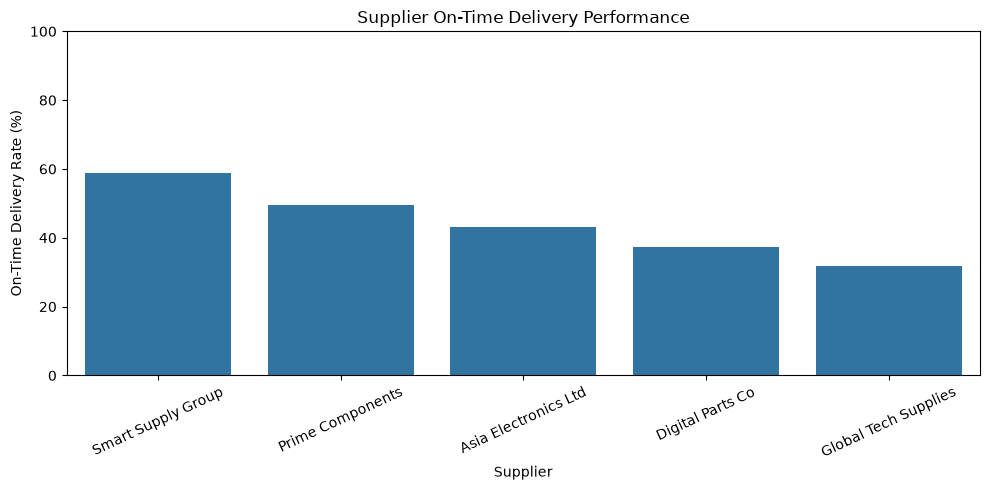

In [177]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=supplier_performance,
    x="supplier_name",
    y="on_time_rate"
)

plt.title("Supplier On-Time Delivery Performance")
plt.xlabel("Supplier")
plt.ylabel("On-Time Delivery Rate (%)")
plt.xticks(rotation=25)
plt.ylim(0, 100)
plt.tight_layout()
plt.show()

In [178]:
delay_analysis = supplier_performance.sort_values(
    "average_delay",
    ascending=False
)

delay_analysis[
    [
        "supplier_name",
        "total_orders",
        "average_delay",
        "delayed_orders",
        "on_time_rate"
    ]
].round(2)

,supplier_name,total_orders,average_delay,delayed_orders,on_time_rate
2,Digital Parts Co,43,1.98,27,37.21
0,Global Tech Supplies,44,1.95,30,31.82
1,Asia Electronics Ltd,58,1.47,33,43.10
3,Prime Components,121,1.02,61,49.59
4,Smart Supply Group,34,0.65,14,58.82


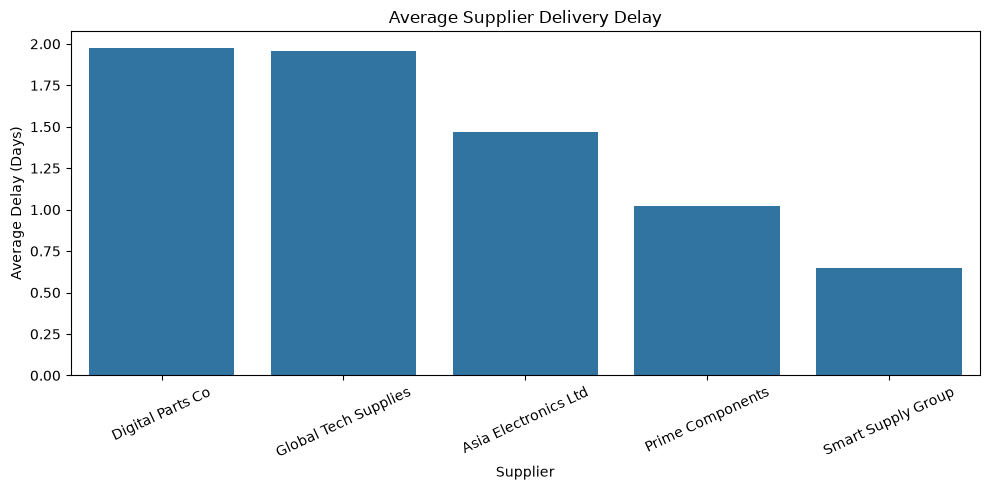

In [179]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=delay_analysis,
    x="supplier_name",
    y="average_delay"
)

plt.title("Average Supplier Delivery Delay")
plt.xlabel("Supplier")
plt.ylabel("Average Delay (Days)")
plt.xticks(rotation=25)
plt.tight_layout()
plt.show()

In [180]:
region_performance = (
    supplier_analysis.groupby("region")
    .agg(
        total_orders=("order_id", "count"),
        average_lead_time=("actual_lead_time_days", "mean"),
        delayed_orders=(
            "delivery_status",
            lambda x: (x == "Delayed").sum()
        )
    )
    .reset_index()
)

region_performance["on_time_rate"] = (
    (region_performance["total_orders"] -
     region_performance["delayed_orders"])
    / region_performance["total_orders"]
) * 100

region_performance.round(2)

,region,total_orders,average_lead_time,delayed_orders,on_time_rate
0,Asia,121,9.02,71,41.32
1,Europe,58,13.47,33,43.10
2,North America,121,16.02,61,49.59


In [181]:
supplier_inventory = (
    inventory.groupby("product_id")["stock_quantity"]
    .sum()
    .reset_index()
)

supplier_inventory = supplier_inventory.merge(
    product_demand[
        ["product_id", "average_daily_demand"]
    ],
    on="product_id"
)

supplier_inventory["days_of_inventory"] = np.where(
    supplier_inventory["average_daily_demand"] > 0,
    supplier_inventory["stock_quantity"] /
    supplier_inventory["average_daily_demand"],
    np.nan
)

In [182]:
supplier_inventory = supplier_inventory.merge(
    products[["product_id", "product_name", "supplier_id"]],
    on="product_id"
)

In [183]:
supplier_stock_risk = (
    supplier_inventory.groupby("supplier_id")
    .agg(
        product_count=("product_id", "nunique"),
        average_inventory_days=("days_of_inventory", "mean"),
        low_coverage_products=(
            "days_of_inventory",
            lambda x: (x < 7).sum()
        )
    )
    .reset_index()
)

supplier_stock_risk = supplier_stock_risk.merge(
    suppliers[["supplier_id", "supplier_name"]],
    on="supplier_id"
)

supplier_stock_risk = supplier_stock_risk.merge(
    supplier_performance[
        ["supplier_id", "on_time_rate", "average_delay"]
    ],
    on="supplier_id"
)

supplier_stock_risk.round(2)

,supplier_id,product_count,average_inventory_days,low_coverage_products,supplier_name,on_time_rate,average_delay
0,1,3,93.55,0,Global Tech Supplies,31.82,1.95
1,2,4,97.45,0,Asia Electronics Ltd,43.10,1.47
2,3,3,78.40,0,Digital Parts Co,37.21,1.98
3,4,8,85.48,0,Prime Components,49.59,1.02
4,5,2,66.96,0,Smart Supply Group,58.82,0.65


In [184]:
from pathlib import Path

REPORT_DIR = Path("../reports")
REPORT_DIR.mkdir(exist_ok=True)

supplier_performance.to_csv(
    REPORT_DIR / "supplier_performance.csv",
    index=False
)

supplier_stock_risk.to_csv(
    REPORT_DIR / "supplier_inventory_risk.csv",
    index=False
)

purchase_orders.to_csv(
    REPORT_DIR / "purchase_orders_analysis.csv",
    index=False
)

print("Supplier analysis reports saved successfully!")

Supplier analysis reports saved successfully!
